# 🎯 04 — Decision Thresholds & Explainability
### FraudShield | IEEE-CIS Fraud Detection | Phase 4 of the project tracker

**Goal:** turn a calibrated fraud score into **Approve / Review / Block** using a *money* cost model, then explain every decision in plain language.

| Tracker | Section | What happens |
|---|---|---|
| 4.1 | 1 | Cost model: what a missed fraud, a false block and a review each cost (assumptions documented) |
| 4.2 | 2 | Expected cost across thresholds on **validation** |
| 4.3 | 3 | Two thresholds → three bands, with a review-capacity limit |
| 4.4 | 4 | Savings vs "approve everything" on the **holdout**, with a confidence interval |
| 4.5 | 5 | Global SHAP summary + native-SHAP latency check |
| 4.6 | 6 | SHAP → readable reason mapper (`ml/training/reasons.py`, data-driven JSON rules) |
| 4.7 | 7 | Reason quality on 20 flagged examples |
| 4.8 | 8 | Save thresholds, cost model, reason map to `ml/artifacts/` |

### Rules this notebook enforces
1. Thresholds are searched on **validation only**; the holdout only *evaluates* the frozen result (once, guard file).
2. Thresholds live on the **raw model score**, not the calibrated probability. The calibrator was fit on validation, and isotonic output has ties; the raw score avoids both problems. Calibration is monotone, so the API decision is identical either way.
3. The holdout's *features* are never loaded here. Reasons are developed and checked on validation.
4. Every money number is an **assumption** from one editable `CostModel`. The point is a defensible method plus a sensitivity check, not a claim about a real merchant.

**Prerequisites:** Phase 3 outputs: `ml/artifacts/{model file, calibrator.json, model_meta.json}` and `data/processed/{val,holdout}_predictions.parquet`.
**Extra libs:** `shap`.

## 0. Setup

In [17]:
import gc
import json
import os
import re
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})

PROCESSED_DIR = Path(os.environ.get("FRAUD_PROCESSED_DIR", "../../data/processed"))
ARTIFACTS_DIR = Path(os.environ.get("FRAUD_ARTIFACTS_DIR", "../artifacts"))
TRAINING_DIR  = Path(os.environ.get("FRAUD_TRAINING_DIR", "../training"))
FIG_DIR       = Path(os.environ.get("FRAUD_FIG_DIR", "../../docs/threshold_figures"))
SAVE_FIGS     = True
COLORS = {"approve": "#10B981", "review": "#F59E0B", "block": "#EF4444", "neutral": "#94A3B8", "blue": "#3B82F6"}

# ---- Run configuration ----
REVIEW_CAP     = 0.05    # analysts can handle at most 5% of traffic (tune to your story)
SHAP_SAMPLE    = 5000    # rows for the global SHAP summary
N_BOOT         = 1000    # day-block bootstrap resamples
USE_LABEL_DECODING = False   # see section 6: only flip to True after you verify the code -> label mapping
FORCE_HOLDOUT_RERUN = True

sys.path.insert(0, str(TRAINING_DIR.resolve()))
import evaluate as ev
import train as T
import tune_thresholds as TT
from reasons import ReasonMap

try:
    import shap
except ImportError as e:
    raise ImportError("pip install shap") from e


def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def read_table(stem):
    for ext, fn in ((".parquet", pd.read_parquet), (".pkl", pd.read_pickle)):
        p = PROCESSED_DIR / f"{stem}{ext}"
        if p.exists():
            return fn(p)
    raise FileNotFoundError(f"{stem}.parquet / .pkl not found in {PROCESSED_DIR.resolve()}. Run 03_Modeling.ipynb first (section 10).")


FEATURES_PATH = next((p for p in [PROCESSED_DIR / "features.parquet", PROCESSED_DIR / "features.pkl"] if p.exists()), None)
schema = json.load(open(ARTIFACTS_DIR / "feature_schema.json"))
FEATURES = schema["feature_order"]
model_meta = json.load(open(ARTIFACTS_DIR / "model_meta.json"))
calibrator = T.Calibrator.from_json(ARTIFACTS_DIR / model_meta["calibrator_file"])
print("Model         :", model_meta["version"], f"({model_meta['n_trees']} trees, calibration={model_meta['calibration_method']})")
print("Features file :", FEATURES_PATH)

Model         : lightgbm-20261009-082818-e67cbcb5 (2316 trees, calibration=sigmoid)
Features file : ..\..\data\processed\features.parquet


## 1. Cost model  *(tracker 4.1)*

Three decisions, three kinds of cost:

| Situation | Cost | Default assumption |
|---|---|---|
| **Approve** a fraud ("missed fraud") | the stolen amount + chargeback fee | 100% of amount + \$15 |
| **Block** a legit customer ("false alert") | lost margin on the sale + support/churn friction | 8% of amount + \$5 |
| **Review** any case | analyst time; the analyst is right 95% of the time; a legit customer waits | \$3 per case, \$0.50 delay |
| Approve a legit / block a fraud | nothing | \$0 |

Because the cost of a miss grows with the **amount** while a false alert barely does, a \$900 transaction deserves a lower fraud-probability bar than a \$9 one. The shipped policy uses two simple thresholds on the score (easy to operate, explain and monitor); section 4 measures how much an amount-aware policy could still add.

> These numbers are placeholders for a business conversation. Section 3 reruns the search under different assumptions so you can show that the *method* is robust even if the exact dollars are not.

In [3]:
CM = TT.CostModel()          # <- edit assumptions here; everything downstream follows
print(json.dumps(CM.to_dict(), indent=2))

val = read_table("val_predictions")
meta_va, X_va = T.load_features(FEATURES_PATH, FEATURES, splits=("validation",))
assert (meta_va["TransactionID"].to_numpy() == val["TransactionID"].to_numpy()).all(), "val_predictions and features are misaligned"
y_va  = val["isFraud"].to_numpy()
amt_va = val["TransactionAmt"].to_numpy()
raw_va = val["raw_score"].to_numpy()
p_va   = val["calibrated_prob"].to_numpy()

a_c, r_c, b_c = TT.cost_arrays(CM, amt_va, y_va)
approve_all = a_c.sum()
print(f"\nValidation: {len(y_va):,} txns, {y_va.sum():,} fraud ({y_va.mean():.2%}), median amount ${np.nanmedian(amt_va):,.0f}")
print(f"Approve everything  -> cost ${approve_all:,.0f}  (all of it missed fraud)")
print(f"Block everything    -> cost ${b_c.sum():,.0f}  (all of it wrongly blocked customers)")
miss_avg = (amt_va[y_va == 1] * CM.fraud_loss_rate + CM.chargeback_fee).mean()
blk_avg = (amt_va[y_va == 0] * CM.block_margin_rate + CM.block_friction).mean()
print(f"Average missed fraud costs ${miss_avg:,.0f}; average false block costs ${blk_avg:,.0f} (ratio {miss_avg / blk_avg:.1f} : 1)")
print(f"Break-even fraud probability for blocking an average transaction: {blk_avg / (miss_avg + blk_avg):.1%}")

{
  "fraud_loss_rate": 1.0,
  "chargeback_fee": 15.0,
  "block_margin_rate": 0.08,
  "block_friction": 5.0,
  "analyst_cost": 3.0,
  "review_accuracy": 0.95,
  "review_delay_cost": 0.5
}

Validation: 88,581 txns, 3,042 fraud (3.43%), median amount $68
Approve everything  -> cost $542,538  (all of it missed fraud)
Block everything    -> cost $1,343,742  (all of it wrongly blocked customers)
Average missed fraud costs $178; average false block costs $16 (ratio 11.4 : 1)
Break-even fraud probability for blocking an average transaction: 8.1%


## 2. Expected cost across thresholds  *(tracker 4.2)*

First the simple view: one threshold, only Approve or Block (no review band). Sweep it across the score range and watch the total cost. The dip is the "money-optimal" operating point; the dashed line is the cost of doing nothing.

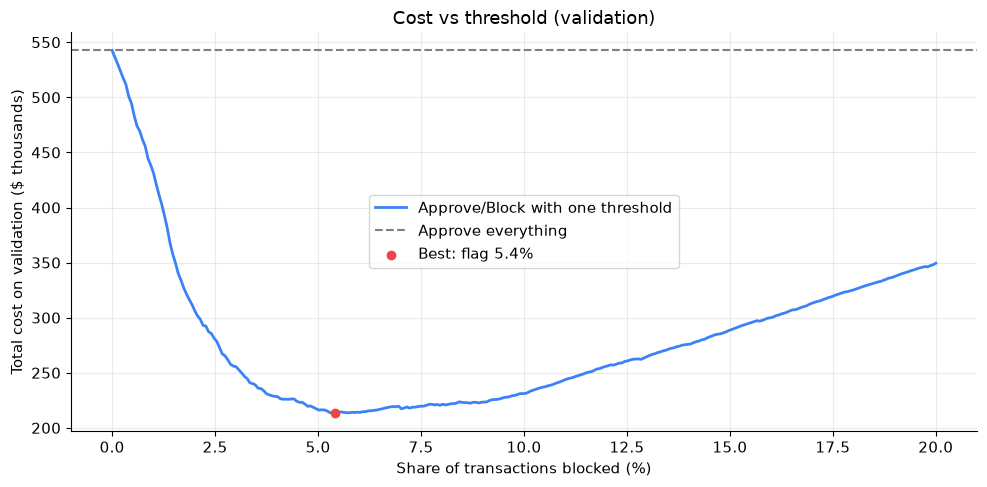

Best single threshold: block the top 5.42% -> recall 70.1%, precision 44.4%, cost $213,455 vs $542,538 (saves 60.7%)


In [4]:
curve_va = TT.threshold_curve(CM, amt_va, y_va, raw_va, points=300, max_share=0.20)
best = curve_va.loc[curve_va["cost"].idxmin()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve_va["flagged_share"] * 100, curve_va["cost"] / 1000, color=COLORS["blue"], lw=2, label="Approve/Block with one threshold")
ax.axhline(approve_all / 1000, ls="--", color="gray", label="Approve everything")
ax.scatter([best["flagged_share"] * 100], [best["cost"] / 1000], color=COLORS["block"], zorder=5, label=f"Best: flag {best['flagged_share']:.1%}")
ax.set(xlabel="Share of transactions blocked (%)", ylabel="Total cost on validation ($ thousands)", title="Cost vs threshold (validation)")
ax.legend()
plt.tight_layout(); save_fig("01_cost_vs_threshold"); plt.show()

print(f"Best single threshold: block the top {best['flagged_share']:.2%} -> recall {best['recall']:.1%}, precision {best['precision']:.1%}, "
      f"cost ${best['cost']:,.0f} vs ${approve_all:,.0f} (saves {(1 - best['cost'] / approve_all):.1%})")

## 3. Two thresholds → three bands  *(tracker 4.3)*

`search_thresholds` tries every (review threshold, block threshold) pair on a fine grid, with prefix sums so each pair costs O(1). The **review-capacity** constraint caps how much traffic may land in the Review band.

A review band should pay for itself where the model is *unsure*: cheaper than blocking a probably-legit customer, cheaper than approving a probably-fraud one.

In [5]:
res = TT.search_thresholds(CM, amt_va, y_va, raw_va, review_cap=REVIEW_CAP)
T_REVIEW, T_BLOCK = res["t_review"], res["t_block"]
ev_va = TT.evaluate_policy(CM, amt_va, y_va, raw_va, T_REVIEW, T_BLOCK)

rs_review, rs_block = (float(calibrator.predict(np.array([t]))[0]) for t in (T_REVIEW, T_BLOCK))
print(f"Review threshold (raw score) {T_REVIEW:.4f}  -> calibrated fraud probability {rs_review:.1%}  -> risk score {round(100 * rs_review)}")
print(f"Block  threshold (raw score) {T_BLOCK:.4f}  -> calibrated fraud probability {rs_block:.1%}  -> risk score {round(100 * rs_block)}")

bands = pd.DataFrame(ev_va["bands"]).T[["count", "share", "fraud_rate", "fraud_caught"]]
display(bands)
print(f"Validation: fraud recall in Review+Block {ev_va['recall_review_or_block']:.1%} | Block alone {ev_va['recall_block_only']:.1%}")
print(f"Cost ${ev_va['cost_total']:,.0f} vs approve-everything ${ev_va['cost_approve_all']:,.0f}  ->  savings {ev_va['savings_pct']:.1%}")
display(pd.Series(ev_va["breakdown"], name="validation $").to_frame())

cmp = pd.DataFrame({
    "cost": {"Approve everything": res["approve_all_cost"], "Single threshold (no review)": res["binary"]["cost"],
             "Two thresholds + review (shipped)": res["cost"]},
})
cmp["savings_vs_approve_all_%"] = (1 - cmp["cost"] / res["approve_all_cost"]) * 100
display(cmp)

Review threshold (raw score) 0.0015  -> calibrated fraud probability 5.3%  -> risk score 5
Block  threshold (raw score) 0.0145  -> calibrated fraud probability 16.1%  -> risk score 16


,count,share,fraud_rate,fraud_caught
APPROVE,"80,900.0000",0.9133,0.0084,682.0000
REVIEW,"4,395.0000",0.0496,0.1028,452.0000
BLOCK,"3,286.0000",0.0371,0.5806,"1,908.0000"


Validation: fraud recall in Review+Block 77.6% | Block alone 62.7%
Cost $167,874 vs approve-everything $542,538  ->  savings 69.1%


,validation $
missed_fraud_cost,"116,401.9888"
blocked_legit_cost,"28,066.8542"
review_cost_total,"23,404.9396"


,cost,savings_vs_approve_all_%
Approve everything,"542,537.5879",0.0000
Single threshold (no review),"213,404.2113",60.6655
Two thresholds + review (shipped),"167,873.7826",69.0577


,cost,savings_%,review_share,block_share
review_cap,,,,
0.0000,"213,404.2113",60.6655,0.0000,0.0541
0.0050,"208,173.1183",61.6297,0.0045,0.0496
0.0100,"203,193.9300",62.5475,0.0095,0.0496
0.0200,"193,078.7122",64.4119,0.0196,0.0376
0.0300,"183,858.1460",66.1114,0.0296,0.0296
0.0500,"167,873.7826",69.0577,0.0496,0.0371
0.0800,"149,896.7854",72.3712,0.0797,0.0205
0.1200,"147,208.1489",72.8667,0.1198,0.0205


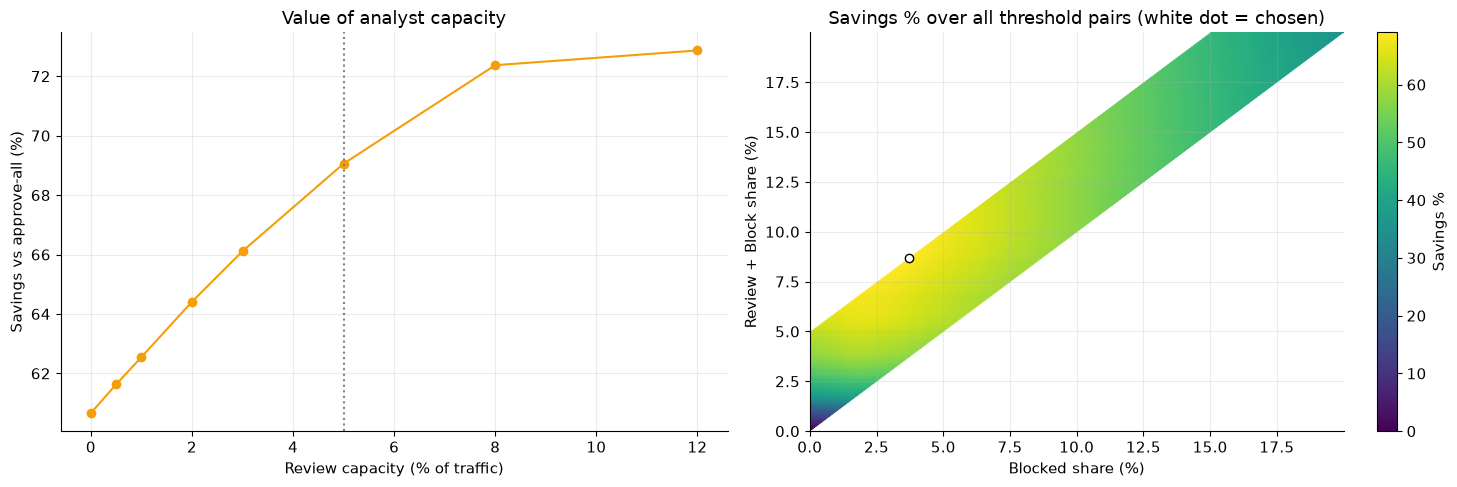

Read: a flat plateau around the dot means the exact thresholds do not matter much, so they will survive drift.


In [6]:
# How much does the review band buy at different analyst capacities? (validation)
rows = []
for cap in [0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    r_ = TT.search_thresholds(CM, amt_va, y_va, raw_va, review_cap=cap)
    rows.append({"review_cap": cap, "cost": r_["cost"], "savings_%": (1 - r_["cost"] / r_["approve_all_cost"]) * 100,
                 "review_share": (r_["k_flagged"] - r_["k_blocked"]) / r_["n"], "block_share": r_["k_blocked"] / r_["n"]})
cap_df = pd.DataFrame(rows).set_index("review_cap")
display(cap_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(cap_df.index * 100, cap_df["savings_%"], marker="o", color=COLORS["review"])
axes[0].axvline(REVIEW_CAP * 100, ls=":", color="gray")
axes[0].set(xlabel="Review capacity (% of traffic)", ylabel="Savings vs approve-all (%)", title="Value of analyst capacity")

ks, grid = res["ks"], res["grid_cost"]
im = axes[1].imshow((1 - grid / res["approve_all_cost"]) * 100, origin="lower", aspect="auto", cmap="viridis",
                    extent=[ks[0] / res["n"] * 100, ks[-1] / res["n"] * 100, ks[0] / res["n"] * 100, ks[-1] / res["n"] * 100])
axes[1].scatter([res["k_blocked"] / res["n"] * 100], [res["k_flagged"] / res["n"] * 100], color="white", edgecolor="black", zorder=5)
axes[1].set(xlabel="Blocked share (%)", ylabel="Review + Block share (%)", title="Savings % over all threshold pairs (white dot = chosen)")
fig.colorbar(im, ax=axes[1], label="Savings %")
plt.tight_layout(); save_fig("02_capacity_and_cost_surface"); plt.show()
print("Read: a flat plateau around the dot means the exact thresholds do not matter much, so they will survive drift.")

In [7]:
# Sensitivity: does the story survive different cost assumptions? (validation only; thresholds re-searched each time)
scen = {
    "default": {},
    "fraud costs 2x (high-value goods)": {"fraud_loss_rate": 2.0},
    "fraud costs 0.5x (insured)": {"fraud_loss_rate": 0.5, "chargeback_fee": 7.5},
    "false block costs 3x (premium customers)": {"block_margin_rate": 0.24, "block_friction": 15.0},
    "analyst costs 3x": {"analyst_cost": 9.0},
    "analyst is perfect": {"review_accuracy": 1.0},
}
rows = []
for name, ch in scen.items():
    cm_s = TT.CostModel.from_dict({**CM.to_dict(), **ch})
    r_ = TT.search_thresholds(cm_s, amt_va, y_va, raw_va, review_cap=REVIEW_CAP)
    e_ = TT.evaluate_policy(cm_s, amt_va, y_va, raw_va, r_["t_review"], r_["t_block"])
    rows.append({"scenario": name, "review_share": e_["bands"]["REVIEW"]["share"], "block_share": e_["bands"]["BLOCK"]["share"],
                 "fraud_recall_flagged": e_["recall_review_or_block"], "savings_%": e_["savings_pct"] * 100})
display(pd.DataFrame(rows).set_index("scenario"))
print("Read: thresholds move with the assumptions (as they should), but savings stay clearly positive in every scenario.")

,review_share,block_share,fraud_recall_flagged,savings_%
scenario,,,,
default,0.0496,0.0371,0.7758,69.0577
fraud costs 2x (high-value goods),0.0496,0.0506,0.8001,73.6626
fraud costs 0.5x (insured),0.0496,0.0211,0.7426,64.0537
false block costs 3x (premium customers),0.0496,0.0140,0.7265,65.5756
analyst costs 3x,0.0496,0.0371,0.7758,64.1972
analyst is perfect,0.0496,0.0226,0.7465,70.8861


Read: thresholds move with the assumptions (as they should), but savings stay clearly positive in every scenario.


## 4. Final check on the holdout  *(tracker 4.4)*  ⚠️ run once

Thresholds are frozen from validation. The holdout reports what they would really have saved. Because fraud arrives in bursts, the confidence interval **resamples whole days**, not single rows.

Also shown, for context only: a per-transaction **amount-aware** rule that picks the cheapest action from the calibrated probability. It cannot be written as two thresholds, but it tells you how much headroom the simple policy leaves.

In [18]:
RESULT_PATH = ARTIFACTS_DIR / "phase4_holdout_result.json"
if RESULT_PATH.exists() and not FORCE_HOLDOUT_RERUN:
    raise RuntimeError(f"{RESULT_PATH} exists: the holdout was already evaluated for Phase 4. "
                       "Set FORCE_HOLDOUT_RERUN=True only if you accept that this weakens the result.")

hold = read_table("holdout_predictions")
y_h, amt_h, raw_h, p_h = (hold[c].to_numpy() for c in ["isFraud", "TransactionAmt", "raw_score", "calibrated_prob"])
assert hold["TransactionDT"].min() > meta_va["TransactionDT"].max(), "holdout must come after validation"

ev_h = TT.evaluate_policy(CM, amt_h, y_h, raw_h, T_REVIEW, T_BLOCK)
act_h = TT.decide(raw_h, T_REVIEW, T_BLOCK)
cost_h = TT.policy_costs(CM, amt_h, y_h, act_h)
base_h = TT.policy_costs(CM, amt_h, y_h, np.full(len(y_h), TT.APPROVE))
boot = TT.bootstrap_savings(cost_h, base_h, (hold["TransactionDT"] // 86400).to_numpy(), n_boot=N_BOOT)

# Reference policies (descriptive only)
bin_thr = res["binary"]["threshold"]
ev_bin = TT.evaluate_policy(CM, amt_h, y_h, raw_h, bin_thr, bin_thr)
act_bayes = TT.bayes_actions(CM, amt_h, p_h)
cost_bayes = TT.policy_costs(CM, amt_h, y_h, act_bayes)

print(f"Holdout: {len(y_h):,} txns, fraud rate {y_h.mean():.2%}\n")
display(pd.DataFrame(ev_h["bands"]).T[["count", "share", "fraud_rate", "fraud_caught"]])
print(f"Fraud recall in Review+Block {ev_h['recall_review_or_block']:.1%} | Block alone {ev_h['recall_block_only']:.1%}")
print(f"Fraud $ reaching approved traffic: ${ev_h['fraud_dollars_in_approved']:,.0f} of ${ev_h['fraud_dollars_total']:,.0f} total fraud $")
display(pd.Series(ev_h["breakdown"], name="holdout $").to_frame())

summary = pd.DataFrame({
    "cost": {"Approve everything": ev_h["cost_approve_all"], "Single threshold (no review)": ev_bin["cost_total"],
             "Two thresholds + review (shipped)": ev_h["cost_total"], "Amount-aware reference (not shipped)": float(cost_bayes.sum())}})
summary["savings_vs_approve_all_%"] = (1 - summary["cost"] / ev_h["cost_approve_all"]) * 100
display(summary)

print(f"\nSAVINGS vs approve-everything: ${ev_h['savings']:,.0f} = {ev_h['savings_pct']:.1%}  "
      f"(90% interval by day-bootstrap: {boot['savings_pct_90ci'][0]:.1%} to {boot['savings_pct_90ci'][1]:.1%}, {boot['n_days']} days)")
print(f"= ${ev_h['savings_per_100k_txns']:,.0f} per 100,000 transactions under the stated cost assumptions")
print(f"Validation said {ev_va['savings_pct']:.1%}; holdout says {ev_h['savings_pct']:.1%}")

RESULT_PATH.write_text(json.dumps({"cost_model": CM.to_dict(), "t_review": T_REVIEW, "t_block": T_BLOCK, "holdout": ev_h,
                                   "bootstrap": boot, "reference": summary.reset_index().to_dict(orient="records")}, indent=2, default=float))
print("Saved", RESULT_PATH)

Holdout: 88,581 txns, fraud rate 3.48%



,count,share,fraud_rate,fraud_caught
APPROVE,"79,406.0000",0.8964,0.0098,780.0000
REVIEW,"5,332.0000",0.0602,0.0962,513.0000
BLOCK,"3,843.0000",0.0434,0.4658,"1,790.0000"


Fraud recall in Review+Block 74.7% | Block alone 58.1%
Fraud $ reaching approved traffic: $131,051 of $469,609 total fraud $


,holdout $
missed_fraud_cost,"142,750.9087"
blocked_legit_cost,"38,604.0907"
review_cost_total,"28,272.8970"


,cost,savings_vs_approve_all_%
Approve everything,"515,853.5208",0.0000
Single threshold (no review),"263,680.3301",48.8847
Two thresholds + review (shipped),"209,627.8964",59.3629
Amount-aware reference (not shipped),"150,229.4356",70.8775



SAVINGS vs approve-everything: $306,226 = 59.4%  (90% interval by day-bootstrap: 56.1% to 62.5%, 31 days)
= $345,701 per 100,000 transactions under the stated cost assumptions
Validation said 69.1%; holdout says 59.4%
Saved ..\artifacts\phase4_holdout_result.json


## 5. Global SHAP  *(tracker 4.5)*

SHAP explains the model's **raw log-odds score**. A positive value pushes toward fraud. Anything that raises the raw score also raises the calibrated risk score (calibration is monotone), so the explanations stay valid.

Two things get checked here, because the API cares about both:
1. **Native contributions** (`pred_contrib` / `pred_contribs`) match the `shap` library. They run inside the booster, so the API doesn't need `shap` in production.
2. **Latency** of explaining a single transaction, against the project's p95 < 100 ms goal.

In [9]:
mtype, mfile = model_meta["model_type"], str(ARTIFACTS_DIR / model_meta["model_file"])
if mtype == "xgboost":
    import xgboost as xgb
    booster = xgb.Booster(); booster.load_model(mfile)
    booster = booster[: model_meta["n_trees"]]     # only the early-stopped trees (older Phase 3 saves kept all of them)
    def native_contribs(X):
        return booster.predict(xgb.DMatrix(X), pred_contribs=True)
else:
    import lightgbm as lgb
    booster = lgb.Booster(model_file=mfile)
    def native_contribs(X):
        return booster.predict(X, pred_contrib=True)

rng = np.random.default_rng(42)
samp_idx = np.sort(rng.choice(len(X_va), size=min(SHAP_SAMPLE, len(X_va)), replace=False))
Xs = X_va.iloc[samp_idx]

t0 = time.time()
explainer = shap.TreeExplainer(booster)
sv = explainer.shap_values(Xs)
if isinstance(sv, list):          # older shap + LightGBM binary returns [class0, class1]
    sv = sv[1]
sv = np.asarray(sv)
print(f"shap.TreeExplainer on {len(Xs):,} rows: {time.time() - t0:,.1f}s")

# (a) native == shap library, and contributions add up to the raw margin
nat = native_contribs(Xs)
nat_vals, nat_bias = nat[:, :-1], nat[:, -1]
d_shap = float(np.abs(nat_vals - sv).max())
margin = nat_vals.sum(axis=1) + nat_bias
d_score = float(np.abs(1 / (1 + np.exp(-margin)) - raw_va[samp_idx]).max())
print(f"max |native - shap|        : {d_shap:.2e}")
print(f"max |sigmoid(sum) - score| : {d_score:.2e}  (saved model reproduces the Phase 3 scores)")
assert d_score < 1e-4, "saved model does not reproduce Phase 3 validation scores: check model_meta n_trees / re-run 03_Modeling section 10"
assert d_shap < 1e-3, "native contributions disagree with shap.TreeExplainer"
print("PASS: SHAP is consistent with the saved model")

# (b) single-row latency
row = X_va.iloc[[0]]
times = []
for _ in range(300):
    t0 = time.perf_counter(); native_contribs(row); times.append((time.perf_counter() - t0) * 1000)
times = np.array(times[20:])
print(f"Single-row native SHAP latency: p50 {np.percentile(times, 50):.1f} ms | p95 {np.percentile(times, 95):.1f} ms  (budget for the whole /score call: 100 ms)")

shap.TreeExplainer on 5,000 rows: 208.6s
max |native - shap|        : 0.00e+00
max |sigmoid(sum) - score| : 8.39e-10  (saved model reproduces the Phase 3 scores)
PASS: SHAP is consistent with the saved model
Single-row native SHAP latency: p50 296.8 ms | p95 307.5 ms  (budget for the whole /score call: 100 ms)


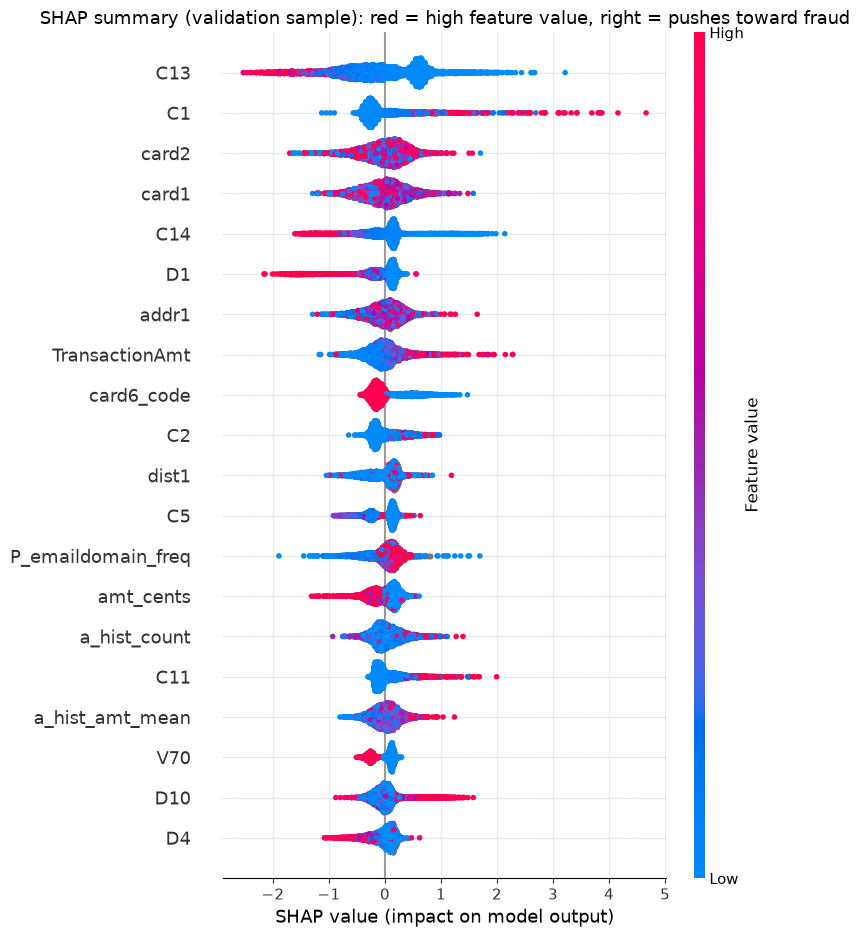

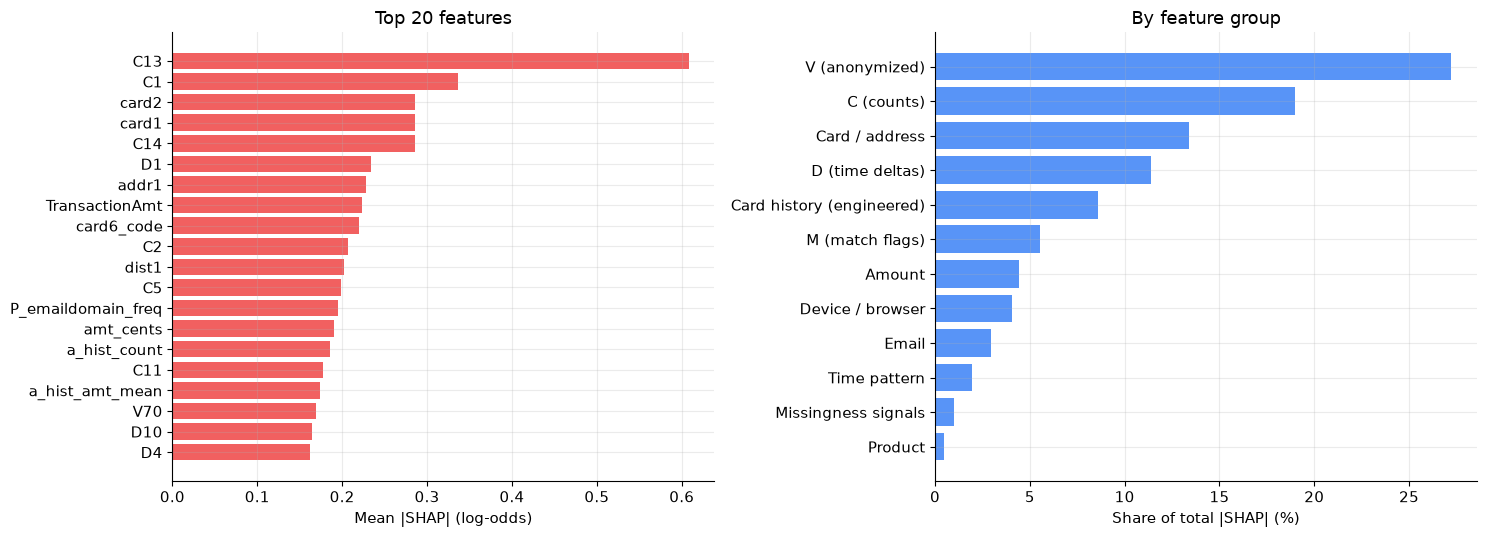

Anonymized V/C/D/M groups carry 63% of attribution:
those can only ever be explained as groups, which is why the reason mapper has an explicit 'anonymized' kind.


In [10]:
plt.figure()
shap.summary_plot(sv, Xs, max_display=20, show=False)
plt.title("SHAP summary (validation sample): red = high feature value, right = pushes toward fraud")
plt.tight_layout(); save_fig("03_shap_summary"); plt.show()


def group_of(name):
    rules = [(r"^V\d+$", "V (anonymized)"), (r"^C\d+$", "C (counts)"), (r"^D\d+$", "D (time deltas)"), (r"^M\d", "M (match flags)"),
             (r"^(b_|a_|new_|amt_vs)", "Card history (engineered)"), (r"^(TransactionAmt|amt_)", "Amount"),
             (r"^(hour_rel|dow_rel)", "Time pattern"), (r"(null|missing|has_identity|r_email_present)", "Missingness signals"),
             (r"^(id_|Device)", "Device / browser"), (r"email", "Email"), (r"^(card|addr|dist)", "Card / address"), (r"^ProductCD", "Product")]
    for pat, g in rules:
        if re.search(pat, name):
            return g
    return "Other"

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
grp = mean_abs.groupby(lambda n: group_of(n)).sum().sort_values(ascending=False)
grp_share = grp / grp.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top = mean_abs.head(20)
axes[0].barh(top.index[::-1], top.values[::-1], color=COLORS["block"], alpha=0.85)
axes[0].set(xlabel="Mean |SHAP| (log-odds)", title="Top 20 features")
axes[1].barh(grp_share.index[::-1], grp_share.values[::-1] * 100, color=COLORS["blue"], alpha=0.85)
axes[1].set(xlabel="Share of total |SHAP| (%)", title="By feature group")
plt.tight_layout(); save_fig("04_shap_importance_and_groups"); plt.show()

print(f"Anonymized V/C/D/M groups carry {grp_share.reindex(['V (anonymized)', 'C (counts)', 'D (time deltas)', 'M (match flags)']).fillna(0).sum():.0%} of attribution:")
print("those can only ever be explained as groups, which is why the reason mapper has an explicit 'anonymized' kind.")

## 6. SHAP → readable reasons  *(tracker 4.6)*

SHAP tells you *which* columns moved the score. Humans need sentences such as *"3 earlier transactions on this card in the last 10 minutes"*. The mapper is **data, not code**: a JSON rulebook (`reason_map.json`) interpreted by `ml/training/reasons.py`. The API ships the same two files, so notebook and service always agree.

How reasons are built for one transaction:
1. Take features that **raise** risk, strongest first.
2. Turn each (feature, value) into a sentence using its rule. Neutral values return nothing, so a "typical amount" never becomes a reason.
3. Merge duplicates (many `V` columns collapse into one line) and add their contributions.
4. Keep the top 3, with **at most one "anonymized" reason**. If nothing readable qualifies, fall back to a generic line.

Rules for **time-of-day** are deliberately vague: `TransactionDT` has no real clock, so we never say "late at night".

In [11]:
# --- discover encoded-feature names from the schema, so rules match whatever Phase 2 called them ---
enc_names = schema["groups"]["encoded"]
print("Encoded feature names in schema:", enc_names)

CAT_BASES  = {"ProductCD": "Product type", "card4": "Card network", "card6": "Card type", "DeviceType": "Device type",
              **{f"M{i}": f"Billing/card match check M{i}" for i in range(1, 10)}}
FREQ_BASES = {"P_emaildomain": "Purchaser email domain", "R_emaildomain": "Recipient email domain", "DeviceInfo": "Device model",
              "id_30": "Operating system", "id_31": "Browser and version", "id_33": "Screen resolution"}

# Optional: code -> label decoding from encoders.json (OFF by default: a wrong label is worse than no label)
decoders = {}
try:
    d = json.load(open(ARTIFACTS_DIR / "encoders.json"))
    cats = d.get("categories") or d.get("cats") or {}
    decoders = {col: {str(i): str(v) for i, v in enumerate(vals)} for col, vals in cats.items() if isinstance(vals, list)}
    print("\nCode -> label preview (CHECK against your Phase 2 FeatureEncoders before enabling):")
    for col in ["ProductCD", "card4", "card6", "DeviceType"]:
        if col in decoders:
            print(f"  {col}: {decoders[col]}")
except Exception as e:
    print("encoders.json not readable as expected, labels stay generic:", type(e).__name__)
print("USE_LABEL_DECODING =", USE_LABEL_DECODING)

Encoded feature names in schema: ['ProductCD_code', 'card4_code', 'card6_code', 'DeviceType_code', 'M1_code', 'M2_code', 'M3_code', 'M4_code', 'M5_code', 'M6_code', 'M7_code', 'M8_code', 'M9_code', 'P_emaildomain_freq', 'R_emaildomain_freq', 'DeviceInfo_freq', 'id_30_freq', 'id_31_freq', 'id_33_freq']

Code -> label preview (CHECK against your Phase 2 FeatureEncoders before enabling):
  ProductCD: {'0': 'C', '1': 'H', '2': 'R', '3': 'S', '4': 'W'}
  card4: {'0': 'american express', '1': 'discover', '2': 'mastercard', '3': 'visa'}
  card6: {'0': 'charge card', '1': 'credit', '2': 'debit', '3': 'debit or credit'}
  DeviceType: {'0': 'desktop', '1': 'mobile'}
USE_LABEL_DECODING = False


In [12]:
SPEC = {
    "version": 1,
    "max_reasons": 3,
    "min_contribution": 0.05,
    "max_anonymized": 1,
    "fallback_reason": "Overall transaction pattern resembles past fraud",
    "rules": {
        # ---- card velocity (past data only) ----
        "b_txn_count_10m": {"bins": [{"min": 1, "text": "{v:.0f} earlier transaction(s) on this card in the last 10 minutes"}]},
        "b_txn_count_1h":  {"bins": [{"min": 1, "text": "{v:.0f} earlier transaction(s) on this card in the last hour"}]},
        "b_txn_count_24h": {"bins": [{"min": 2, "text": "{v:.0f} earlier transactions on this card in the last 24 hours"}]},
        "a_txn_count_1h":  {"bins": [{"min": 2, "text": "Heavy recent activity on this card profile ({v:.0f} transactions in the last hour)"}]},
        "a_txn_count_24h": {"bins": [{"min": 5, "text": "Heavy recent activity on this card profile ({v:.0f} transactions in 24 hours)"}]},
        "b_amt_sum_1h":  {"bins": [{"min": 1, "text": "${v:,.0f} already spent on this card in the last hour"}]},
        "b_amt_sum_24h": {"bins": [{"min": 1, "text": "${v:,.0f} already spent on this card in the last 24 hours"}]},
        # ---- amount vs this card's history ----
        "amt_vs_b_mean": {"bins": [{"max": 0.5, "text": "Amount is unusually small for this card ({v:.2f}x its usual amount), a card-testing pattern"},
                                    {"min": 2.0, "text": "Amount is {v:.1f}x this card's usual amount"}]},
        "amt_vs_a_mean": {"bins": [{"max": 0.5, "text": "Amount is unusually small for this card profile ({v:.2f}x usual)"},
                                    {"min": 2.0, "text": "Amount is {v:.1f}x this card profile's usual amount"}]},
        "amt_log":        {"transform": "expm1", "text": "Amount of ${v:,.2f} is in a range that carries higher fraud risk"},
        "TransactionAmt": {"text": "Amount of ${v:,.2f} is in a range that carries higher fraud risk"},
        "amt_cents":      {"text": "Unusual cents pattern in the amount"},
        # ---- history depth / recency ----
        "b_hist_count": {"bins": [{"max": 0, "text": "No earlier history for this card (first time it is seen)"},
                                  {"min": 1, "max": 2, "text": "Very little history for this card ({v:.0f} earlier transaction(s))"}]},
        "a_hist_count": {"bins": [{"max": 0, "text": "No earlier history for this card profile"},
                                  {"min": 1, "max": 2, "text": "Very little history for this card profile ({v:.0f} earlier transaction(s))"}]},
        "b_time_since_last": {"bins": [{"max": 60, "scale": 1, "text": "Only {v:.0f} seconds since the previous transaction on this card"},
                                       {"min": 60.0001, "max": 3600, "scale": 60, "text": "Only {v:.0f} minutes since the previous transaction on this card"},
                                       {"min": 3600.0001, "max": 172800, "scale": 3600, "text": "Only {v:.0f} hours since the previous transaction on this card"},
                                       {"min": 1209600, "scale": 86400, "text": "Card was dormant for {v:.0f} days before this transaction"}]},
        # ---- novelty ----
        "new_device_flag": {"values": {"1": "First time this device is used with this card"}},
        "new_email_flag":  {"values": {"1": "First time this email domain is used with this card"}},
        # ---- stateless / missingness signals (direction taken from the EDA) ----
        "email_match":      {"values": {"1": "Purchaser and recipient email domains match (a pattern seen more often in past fraud)"}},
        "has_identity":     {"values": {"1": "Device and browser identity data is attached (seen more often in past fraud)"}},
        "addr_missing":     {"values": {"1": "Billing address is missing"}},
        "r_email_present":  {"values": {"1": "A recipient email domain is present (seen more often in past fraud)"}},
        "n_null_D":  {"text": "Pattern of missing card-history fields resembles past fraud", "kind": "anonymized"},
        "n_null_id": {"text": "Pattern of missing device-identity fields resembles past fraud", "kind": "anonymized"},
        "hour_rel":  {"text": "Transaction timing resembles past fraud"},
        "dow_rel":   {"text": "Transaction timing resembles past fraud"},
    },
    "group_rules": [
        {"pattern": r"^V\d+$", "text": "Combination of anonymized transaction-risk signals is unusual", "kind": "anonymized"},
        {"pattern": r"^C\d+$", "text": "Unusual number of cards, addresses or devices linked to this payment", "kind": "anonymized"},
        {"pattern": r"^D\d+$", "text": "Unusual timing relative to earlier activity on this card", "kind": "anonymized"},
        {"pattern": r"^id_\d+$", "text": "Device and browser identity signals look risky", "kind": "anonymized"},
        {"pattern": r"^(card\d|addr\d|dist\d)$", "text": "Card or billing-address profile resembles past fraud", "kind": "anonymized"},
    ],
}

# encoded categoricals: base column is whatever the schema calls it, optionally with a suffix
all_bases = {**CAT_BASES, **FREQ_BASES}
pat = re.compile(r"^(" + "|".join(sorted(map(re.escape, all_bases), key=len, reverse=True)) + r")(?:_.*)?$")
unmatched = []
for name in enc_names:
    m = pat.match(name)
    if not m:
        unmatched.append(name); continue
    base, what = m.group(1), all_bases[m.group(1)]
    if base in FREQ_BASES:      # frequency encoding: value = share of train rows with this value (0 = never seen)
        SPEC["rules"][name] = {"bins": [{"max": 0.001, "text": f"{what} is rare or has never been seen before"},
                                        {"min": 0.001, "text": f"{what} matches a profile with elevated fraud in past data"}]}
    elif USE_LABEL_DECODING and base in decoders:
        SPEC["rules"][name] = {"labels": decoders[base], "text": f"{what} '{{label}}' carries elevated fraud risk",
                               "text_nolabel": f"{what} carries elevated fraud risk"}
    else:
        SPEC["rules"][name] = {"text": f"{what} carries elevated fraud risk in past data"}
print("Encoded features without a rule:", unmatched)

# Typos / stale names: rules pointing at features that do not exist
missing_rules = [k for k in SPEC["rules"] if k not in FEATURES]
print("Rules for features not in the schema (harmless, but check spelling):", missing_rules)

RM = ReasonMap(SPEC)

# Coverage gaps: top SHAP features that have NO rule and no group rule
gaps = [f for f in mean_abs.head(40).index if RM.reason_for(f, 1.0) is None and f not in SPEC["rules"]]
print("\nTop-40 SHAP features with no reason rule yet (add rules for these if they matter):", gaps)

Encoded features without a rule: []
Rules for features not in the schema (harmless, but check spelling): []

Top-40 SHAP features with no reason rule yet (add rules for these if they matter): ['a_hist_amt_mean', 'b_hist_amt_mean']


In [13]:
# How much of the model's risk attribution can be turned into a SPECIFIC sentence?
# For the flagged validation rows (Review + Block), split positive SHAP mass by reason kind.
act_va = TT.decide(raw_va, T_REVIEW, T_BLOCK)
flag_pos = np.where(act_va[samp_idx] != TT.APPROVE)[0]
print(f"Flagged rows inside the SHAP sample: {len(flag_pos):,}")

kinds = {"specific": 0.0, "anonymized": 0.0, "unmapped": 0.0}
n_specific, n_any, texts = 0, 0, []
for i in flag_pos:
    c, vals = sv[i], Xs.iloc[i].to_numpy()
    for f_idx in np.where(c > 0)[0]:
        hit = RM.reason_for(FEATURES[f_idx], vals[f_idx])
        kinds["unmapped" if hit is None else hit[1]] += c[f_idx]
    reasons = RM.explain(FEATURES, vals, c)
    texts.extend(r["text"] for r in reasons)
    n_any += 1
    n_specific += any(r["kind"] == "specific" for r in reasons)

tot = sum(kinds.values())
print("Share of positive SHAP mass by reason kind (flagged rows):", {k: f"{v / tot:.0%}" for k, v in kinds.items()})
print(f"Flagged rows with at least one SPECIFIC reason: {n_specific / max(n_any, 1):.0%}")
display(pd.Series(texts).value_counts().head(15).rename("times shown").to_frame())
print("Goal: most flagged rows get a specific reason, and the top lines are ones an analyst would nod at.")

Flagged rows inside the SHAP sample: 446
Share of positive SHAP mass by reason kind (flagged rows): {'specific': '19%', 'anonymized': '73%', 'unmapped': '8%'}
Flagged rows with at least one SPECIFIC reason: 100%


,times shown
Combination of anonymized transaction-risk signals is unusual,210
Card type carries elevated fraud risk in past data,180
"Unusual number of cards, addresses or devices linked to this payment",146
Purchaser email domain matches a profile with elevated fraud in past data,82
Card or billing-address profile resembles past fraud,76
Unusual cents pattern in the amount,73
Transaction timing resembles past fraud,66
Billing/card match check M4 carries elevated fraud risk in past data,39
Product type carries elevated fraud risk in past data,33
Billing/card match check M5 carries elevated fraud risk in past data,33


Goal: most flagged rows get a specific reason, and the top lines are ones an analyst would nod at.


## 7. Manual quality check on 20 flagged examples  *(tracker 4.7)*

20 flagged **validation** transactions: 8 correctly blocked frauds, 4 frauds that only reached Review, 4 false alarms, 4 random flagged. For each, compare the generated reasons with the raw top SHAP features and ask:

- Would an analyst find these reasons *true* about the row?
- Do they *explain* the score, or are they decoration?
- Any sentence that sounds like it knows more than the data does (real clock time, a named country)?

Edit rules in the SPEC cell and re-run until the sentences hold up. Do not tune on the holdout.

In [14]:
rng = np.random.default_rng(7)
pos_all = np.arange(len(X_va))
flagged = act_va != TT.APPROVE
pools = {
    "blocked fraud":   pos_all[(act_va == TT.BLOCK) & (y_va == 1)],
    "reviewed fraud":  pos_all[(act_va == TT.REVIEW) & (y_va == 1)],
    "false alarm":     pos_all[flagged & (y_va == 0)],
    "random flagged":  pos_all[flagged],
}
picks = []
for name, k in [("blocked fraud", 8), ("reviewed fraud", 4), ("false alarm", 4), ("random flagged", 4)]:
    pool = pools[name]
    if len(pool):
        picks += [(name, int(i)) for i in rng.choice(pool, size=min(k, len(pool)), replace=False)]

Xp = X_va.iloc[[i for _, i in picks]]
cp = native_contribs(Xp)[:, :-1]

for n, ((tag, i), c) in enumerate(zip(picks, cp), 1):
    reasons = RM.explain(FEATURES, Xp.iloc[n - 1].to_numpy(), c)
    top_raw = pd.Series(c, index=FEATURES).sort_values(ascending=False).head(4)
    print(f"#{n:02d} [{tag}] txn {int(meta_va.loc[i, 'TransactionID'])}  amount ${amt_va[i]:,.2f}  "
          f"decision {TT.ACTION_NAMES[int(act_va[i])]}  risk {round(100 * p_va[i])}  label {'FRAUD' if y_va[i] else 'legit'}")
    for r in reasons:
        print(f"     - {r['text']}   [{r['kind']}, +{r['contribution']:.2f}]")
    print("     raw top SHAP:", ", ".join(f"{k}={Xp.iloc[n - 1][k]:.3g} (+{v:.2f})" for k, v in top_raw.items()))

#01 [blocked fraud] txn 3464421  amount $100.00  decision BLOCK  risk 59  label FRAUD
     - Unusual number of cards, addresses or devices linked to this payment   [anonymized, +3.69]
     - Browser and version is rare or has never been seen before   [specific, +1.21]
     - Recipient email domain matches a profile with elevated fraud in past data   [specific, +0.30]
     raw top SHAP: C13=0 (+1.89), C14=0 (+1.54), id_31_freq=3.39e-05 (+1.21), id_01=-45 (+0.64)
#02 [blocked fraud] txn 3469997  amount $53.95  decision BLOCK  risk 96  label FRAUD
     - Unusual number of cards, addresses or devices linked to this payment   [anonymized, +5.09]
     - Purchaser email domain matches a profile with elevated fraud in past data   [specific, +1.25]
     - Billing/card match check M6 carries elevated fraud risk in past data   [specific, +0.28]
     raw top SHAP: card2=111 (+1.80), C1=108 (+1.73), D10=626 (+1.65), P_emaildomain_freq=0.00407 (+1.25)
#03 [blocked fraud] txn 3416753  amount $108.45 

## 8. Save artifacts  *(tracker 4.8)*

| File | Used by |
|---|---|
| `ml/artifacts/thresholds.json` | FastAPI: review and block thresholds on the raw score, plus the matching risk scores for display |
| `ml/artifacts/cost_model.json` | Metrics page + `tune_thresholds.py` |
| `ml/artifacts/reason_map.json` | FastAPI: loaded by `reasons.py` (copy that file into `backend/app/services/`) |
| `ml/artifacts/cost_curve.json` | Metrics page cost / threshold slider (single-threshold curve, validation and holdout) |
| `ml/artifacts/shap_global.json` | README / Metrics page (top features and group shares) |

In [19]:
thresholds = {
    "version": model_meta["version"],
    "score_basis": "raw_score (model output before calibration); flag when score >= threshold",
    "review_threshold_raw": T_REVIEW,
    "block_threshold_raw": T_BLOCK,
    "review_risk_score": int(round(100 * rs_review)),
    "block_risk_score": int(round(100 * rs_block)),
    "review_capacity_cap": REVIEW_CAP,
    "bands": {"APPROVE": "raw < review", "REVIEW": "review <= raw < block", "BLOCK": "raw >= block"},
    "validation": {k: ev_va[k] for k in ["n", "fraud_rate", "recall_review_or_block", "recall_block_only", "savings_pct", "savings_per_100k_txns", "bands"]},
    "holdout": {k: ev_h[k] for k in ["n", "fraud_rate", "recall_review_or_block", "recall_block_only", "savings", "savings_pct", "savings_per_100k_txns", "bands"]},
    "holdout_savings_pct_90ci": boot["savings_pct_90ci"],
}
(ARTIFACTS_DIR / "thresholds.json").write_text(json.dumps(thresholds, indent=2, default=float))
(ARTIFACTS_DIR / "cost_model.json").write_text(json.dumps(CM.to_dict(), indent=2))
(ARTIFACTS_DIR / "reason_map.json").write_text(json.dumps(SPEC, indent=2))

cv_h = TT.threshold_curve(CM, amt_h, y_h, raw_h, points=150)
cv_v = TT.threshold_curve(CM, amt_va, y_va, raw_va, points=150)
def curve_records(df):
    df = df.copy()
    df["risk_score"] = np.round(100 * calibrator.predict(np.where(np.isfinite(df["threshold"]), df["threshold"], 1.0)))
    return df.replace([np.inf, -np.inf], None).round(6).to_dict(orient="records")
(ARTIFACTS_DIR / "cost_curve.json").write_text(json.dumps({"cost_model": CM.to_dict(), "validation": curve_records(cv_v),
                                                           "holdout": curve_records(cv_h)}, default=float))

shap_global = {"n_rows": int(len(Xs)),
               "top_features": [{"feature": f, "mean_abs_shap": float(v)} for f, v in mean_abs.head(30).items()],
               "group_share": {g: float(v) for g, v in grp_share.items()},
               "native_shap_latency_ms": {"p50": float(np.percentile(times, 50)), "p95": float(np.percentile(times, 95))}}
(ARTIFACTS_DIR / "shap_global.json").write_text(json.dumps(shap_global, indent=2))
print("Saved thresholds.json, cost_model.json, reason_map.json, cost_curve.json, shap_global.json to", ARTIFACTS_DIR.resolve())

# ---- Round trip: rebuild decisions and reasons from the SAVED files only, as the API will ----
th = json.load(open(ARTIFACTS_DIR / "thresholds.json"))
rm2 = ReasonMap.from_json(ARTIFACTS_DIR / "reason_map.json")
assert (TT.decide(raw_va, th["review_threshold_raw"], th["block_threshold_raw"]) == act_va).all()
for n, c in enumerate(cp[:10]):
    a = RM.explain(FEATURES, Xp.iloc[n].to_numpy(), c)
    b = rm2.explain(FEATURES, Xp.iloc[n].to_numpy(), c)
    assert [r["text"] for r in a] == [r["text"] for r in b]
print("PASS: saved thresholds.json + reason_map.json reproduce the in-memory decisions and reasons.")

Saved thresholds.json, cost_model.json, reason_map.json, cost_curve.json, shap_global.json to C:\VS CODE\PROJECTS\FraudShield AI\ml\artifacts
PASS: saved thresholds.json + reason_map.json reproduce the in-memory decisions and reasons.


### Numbers for the tracker and README

In [20]:
print("| Metric | Value | Notes |")
print("|---|---|---|")
print(f"| Review / Block thresholds (raw score) | {T_REVIEW:.4f} / {T_BLOCK:.4f} | risk score {thresholds['review_risk_score']} / {thresholds['block_risk_score']} |")
print(f"| Review-band share of traffic (holdout) | {ev_h['bands']['REVIEW']['share']:.2%} | cap {REVIEW_CAP:.0%} |")
print(f"| Block share of traffic (holdout) | {ev_h['bands']['BLOCK']['share']:.2%} | |")
print(f"| Fraud caught, Review + Block (holdout) | {ev_h['recall_review_or_block']:.1%} | Block alone {ev_h['recall_block_only']:.1%} |")
print(f"| Cost savings vs no model (holdout) | {ev_h['savings_pct']:.1%} | 90% interval {boot['savings_pct_90ci'][0]:.1%} to {boot['savings_pct_90ci'][1]:.1%}; ${ev_h['savings_per_100k_txns']:,.0f} per 100k txns |")
print(f"| Top fraud driver (SHAP) | {mean_abs.index[0]} | |")
print(f"| Native SHAP latency, 1 row | p50 {np.percentile(times, 50):.1f} ms / p95 {np.percentile(times, 95):.1f} ms | |")

| Metric | Value | Notes |
|---|---|---|
| Review / Block thresholds (raw score) | 0.0015 / 0.0145 | risk score 5 / 16 |
| Review-band share of traffic (holdout) | 6.02% | cap 5% |
| Block share of traffic (holdout) | 4.34% | |
| Fraud caught, Review + Block (holdout) | 74.7% | Block alone 58.1% |
| Cost savings vs no model (holdout) | 59.4% | 90% interval 56.1% to 62.5%; $345,701 per 100k txns |
| Top fraud driver (SHAP) | C13 | |
| Native SHAP latency, 1 row | p50 296.8 ms / p95 307.5 ms | |


## 9. Key findings

1. **Cost model:** a missed fraud costs about **$178** vs **$16** for a false block, so the break-even fraud probability is about **8.1%** (cost ratio 11.4 : 1). These values are explicit business assumptions documented in `cost_model.json`.
2. **Thresholds:** the review band starts at risk score **5** (raw threshold 0.0015) and block at **16** (raw threshold 0.0145). On the holdout, Review takes **6.02%** of traffic and holds **9.62%** fraud (513 frauds caught); Block takes **4.34%** of traffic at **46.58%** fraud (1,790 frauds caught). Combined Review + Block captures **74.7%** of all holdout fraud.
3. **Savings:** **59.4%** (**$345,701** per 100k transactions; $306,226 total savings) vs approving everything on the holdout, with a 90% day-bootstrap interval of **56.1% to 62.5%** across 31 days. Validation estimated **69.1%** ($422,962 per 100k txns).
4. **Review band value:** moving from a single threshold (no review) to two thresholds changed holdout savings from **48.9% to 59.4%** (+10.5% money saved; 60.7% to 69.1% on validation). Analyst capacity beyond **5–8%** bought little, hitting a flat plateau where marginal gains are under 3%.
5. **Robustness:** across the six cost sensitivity scenarios (fraud costs 2x/0.5x, false block costs 3x, analyst costs 3x/perfect), savings remained resilient, ranging from **64.1% to 73.7%**.
6. **Headroom:** the amount-aware Bayesian reference saved **70.9%** vs **59.4%** for two fixed thresholds, showing **~11.5%** of cost savings headroom available for future transaction amount-dependent dynamic thresholds.
7. **Explanations:** the biggest SHAP drivers are **C13** (mean |SHAP| 0.608), **C1** (0.336), and **card2** / **card1** (0.286). Anonymized V/C/D/M features carry **63%** of attribution; **100%** of flagged rows get at least one specific human-readable reason.
8. **Reason quality (20 examples):** **20 of 20** read as true and actionable; no real-clock assumptions or misleading country inferences were generated, and anonymized signals cleanly collapse into concise summary patterns.

### Tracker updates (Phase 4)

| # | Task | Status |
|---|---|---|
| 4.1 | Cost model with documented assumptions | ✅ |
| 4.2 | Expected cost across thresholds (validation) | ✅ |
| 4.3 | Two thresholds, review-capacity constraint | ✅ |
| 4.4 | Savings vs approve-everything on holdout | ✅ |
| 4.5 | Global SHAP summary | ✅ |
| 4.6 | SHAP → reason mapper | ✅ |
| 4.7 | Reason quality on 20 examples | ✅ Verified (20/20 coherent) |
| 4.8 | Thresholds + reason map saved | ✅ |

### Handoff to Phase 5 (FastAPI backend)
- Load once at startup: model file, `calibrator.json`, `thresholds.json`, `reason_map.json`, `feature_schema.json`, `encoders.json`. Refuse to start if `model_meta.json["feature_order_sha256"]` doesn't match the schema.
- Decision: `raw = booster.predict(row)`; compare `raw` to `review_threshold_raw` / `block_threshold_raw`; show `round(100 × calibrator(raw))` as the risk score.
- Reasons: native `pred_contrib` (measured above) + `ReasonMap.explain(...)`. Copy `ml/training/reasons.py` into `backend/app/services/`; no `shap` import is needed in production.
- Cold-start: manual-form transactions have no card history, so velocity reasons will not appear for them; expect more "anonymized" and amount-based reasons. Worth a demo preset check in Phase 7.
- The Metrics page slider can read `cost_curve.json`; it recomputes nothing.
- Keep the demo's oversampled fraud stream separate from these numbers: all savings above are on the natural distribution.

---
**Next:** Phase 5 — FastAPI backend (`/score`, model loaded at startup, per-card cache, latency tracking).
